### EMERGENT Analysis: Notebook 8
#### Cluster analysis to identify latent groups of clinical profiles based on DHMs

In this notebook, an unsupervised cluster analysis approach is taken to examine whether DHMs map onto clinical profiles. This approach uses the following steps: 

1. Use k-means approach to cluster patients into 2 or 3 groups based on data from the entire sample
   - First cluster patients based on symptoms (PANSS-P, PANSS-N, PANSS-G)
   - Next cluster patients based on DHMs
   - Determine whether these clusters overlap, indicating whether DHMs, on the whole, identify similar groups to the symptom clusters.
2. See how clinical scores for these clusters change over time
   - Do this first for the symptom clusters
   - Then for the clusters derived based on DHMs
   - Determine whether any subgroups of patients as identified by DHMs have a more clear longitudinal trajectory -- would we be able to identify these earlier on
3. See how treatment group affects symptom change over time for each cluster
   - Do this first for the symptom clusters
   - Then again for the clusters derived based on DHMs
   - If different clusters show differential response to treatment, we may be able to identify these patients earlier on in the context of trial enrichment or stratification.
4. Visualization of results to determine the importance of DHM "profiles" in characterizing symptoms
   - To better undertsand the characteristics of each cluster, radar charts were created showing different levels of DHMs for each cluster. The primary chart of interest is the one showing levels of DHMs for the symptom-identified clusters as distinct levels of DHMs mapping onto distinct symptom clusters would be a way of validating the use of DHMs in identifying these clusters.
   - For example, there is one symptom cluster that shows high levels of negative symptoms at baseline that significantly improve over the course of the study. Showing DHMs that specifically map onto this group would be meaningful in validating this distinct profile vs other symptom profiles. 

### 1 - Setup

Load necessary packages, define relevant paths for data and storing figures.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import scipy.stats as stats
import seaborn as sns
from tqdm import tqdm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score 
from scipy.stats import pearsonr
import plotly.express as px

from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans

import sys
sys.path.append('/home/ssm-user/bklynhlth-science/common_functions/')
from analysis import (
    scatterplot, boxplot_ttest, distribution,
    calculate_labelpad_and_left, mlr_test, cohens_d, lme_test,
    train_and_test, plot_feature_importance, scatterplot_rmse,
    train_rf_model, test_rf_model, boxplot_sites_multiple,
    boxplot_anova, distribution_grid, boxplot_sites, boxplot_sites_adj, 
    tukey_anova, boxplot_visits, boxplot_visits_multiple, boxplot_sites,
    response_to_treatment
)
from study_data import remove_outliers

pd.set_option('display.max_rows', None)
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
def map_visit_names(df):
    """
    Maps 'visit' to 'visit_name' based on 'studyid' using predefined mappings.

    Args:
    -------
        df (pandas.DataFrame): DataFrame with 'studyid', 'visit', and 'visit_name' columns.

    Returns:
    -------
        pandas.DataFrame: DataFrame with 'visit_name' mapped according to 'studyid' and 'visit'.
    """

    def apply_mapping(row):
        study_mappings = {
            'kar004': {
                1: 'SCR',
                2: 'BL',
                6: 'V6',
                8: 'V8',
                9: 'V9/EOT',
            },
            'kar007': {
                1: 'SCR',
                2: 'BL',
                7: 'V6',
                8: 'V7',
                9: 'V8',
                11: 'V10/EOT',
                12: 'SF'
            },
            'kar009': {
                1: 'SCR',
                2: 'BL',
                7: 'V6',
                8: 'V7',
                9: 'V8',
                11: 'V10/EOT',
                12: 'SF'
            }
        }
        study_id = row['study']
        visit = row['visit']
        return study_mappings.get(study_id, {}).get(visit)

    df['visit_name'] = df.apply(apply_mapping, axis=1)
    return df

In [3]:
figure_dir = '/home/ssm-user/bklynhlth-science/michelleworthington/emergent_analysis/figures/final_figures/notebook8_clustering/'

#### 1.1 - Load data

Load compiled data from first notebook. 

In [4]:
df = pd.read_csv('/home/ssm-user/bklynhlth-science/datasets/datasets_engagements/emergent/emergent_analysis_df.csv')

In [5]:
# define DHMs
dhms = ['file_length', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness',
       'first_person_percentage',
       'first_person_sentiment_positive', 'first_person_sentiment_negative',
       'first_person_sentiment_overall', 'word_repeat_percentage',
       'phrase_repeat_percentage',
       'word_coherence_mean', 'word_coherence_var', 'word_coherence_5_mean',
       'word_coherence_5_var', 'word_coherence_10_mean',
       'word_coherence_10_var', 'word_coherence_variability_2_mean',
       'word_coherence_variability_2_var', 'word_coherence_variability_3_mean',
       'word_coherence_variability_3_var', 'word_coherence_variability_4_mean',
       'word_coherence_variability_4_var', 'word_coherence_variability_5_mean',
       'word_coherence_variability_5_var', 'word_coherence_variability_6_mean',
       'word_coherence_variability_6_var', 'word_coherence_variability_7_mean',
       'word_coherence_variability_7_var', 'word_coherence_variability_8_mean',
       'word_coherence_variability_8_var', 'word_coherence_variability_9_mean',
       'word_coherence_variability_9_var',
       'word_coherence_variability_10_mean',
       'word_coherence_variability_10_var',
       'first_order_sentence_tangeniality_mean',
       'first_order_sentence_tangeniality_var',
       'second_order_sentence_tangeniality_mean',
       'second_order_sentence_tangeniality_var',
       'turn_to_turn_tangeniality_mean', 'turn_to_turn_tangeniality_var',
       'turn_to_turn_tangeniality_slope', 'semantic_perplexity_mean',
       'semantic_perplexity_var', 'f0_mean', 'f0_stddev', 'f1_mean', 'f1_stddev', 
       'f2_mean', 'f2_stddev', 'f3_mean', 'f3_stddev', 'f4_mean', 'f4_stddev',
       'loudness_mean', 'loudness_stddev', 'hnr_mean',
       'hnr_stddev', 'jitter', 'jitter_abs',
       'jitter_rap', 'jitter_ppq5', 'jitter_ddp', 'shimmer', 'shimmer_db',
       'shimmer_apq3', 'shimmer_apq5', 'shimmer_apq11', 'shimmer_dda',
       'gne_ratio', 'silence_ratio']

In [6]:
# creating a dataframe that has data from screening only

df_screening = df[df['visit'] == 1].drop_duplicates(subset='id', keep='first')

In [7]:
df_clean = remove_outliers(df.copy(), dhms)
df_screening_clean = remove_outliers(df_screening.copy(), dhms)

In [8]:
df_clean.describe()

,age,male,white,black,asian,native/hawaiin pacific islander,arm,visit,panss_p1,panss_p2,...,shimmer_apq3,shimmer_apq5,shimmer_apq11,shimmer_dda,gne_ratio,pause_meandur,pause_rate,silence_ratio,speech_length_in_minutes_adjusted,speech_length_in_words_adjusted
count,3947.000000,3947.000000,3947.000000,3947.000000,3947.000000,882.000000,3676.000000,3947.000000,3947.000000,3947.000000,...,3475.000000,3459.000000,3431.000000,3475.000000,3475.000000,3478.000000,3485.000000,3454.000000,3479.000000,3423.000000
mean,44.277426,0.752724,0.278439,0.701545,0.010388,0.011338,0.513330,5.685077,4.393717,3.051938,...,0.070273,0.100101,0.163673,0.210819,0.831094,0.712828,6.541992,49.893190,0.343547,45.366492
std,11.079234,0.431483,0.448288,0.457638,0.101402,0.105934,0.534102,3.884076,1.043912,1.241326,...,0.012588,0.016324,0.024753,0.037763,0.041463,0.091259,3.694629,12.039155,0.160545,23.963375
min,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.035330,0.055485,0.096620,0.105989,0.710199,0.500000,0.000000,19.589437,0.005669,0.697378
25%,35.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,4.000000,2.000000,...,0.061562,0.089016,0.147227,0.184685,0.800979,0.657174,3.935355,41.073399,0.216223,26.074298
50%,45.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,7.000000,4.000000,3.000000,...,0.070440,0.100287,0.163253,0.211319,0.834759,0.696530,5.906080,48.870901,0.325462,42.172227
75%,53.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,9.000000,5.000000,4.000000,...,0.079142,0.111330,0.180260,0.237425,0.861772,0.749394,8.528928,57.888445,0.455907,61.332144
max,65.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000,12.000000,7.000000,7.000000,...,0.105009,0.144850,0.231455,0.315028,0.949814,2.541800,31.241809,83.180234,0.808423,116.050194


### 2 - Clustering based on symptom profiles

#### 2.1 - Prep data for clustering

First will cluster just based on different values for positive, negative, and general symptoms. 

In [9]:
symptom_data = df_clean[['panss_ptot', 'panss_ntot', 'panss_gtot']]

In [10]:
item_data = df_clean[['panss_p1', 'panss_p2', 'panss_p3',
 'panss_p4', 'panss_p5', 'panss_p6', 'panss_p7', 'panss_n1',
 'panss_n2', 'panss_n3', 'panss_n4', 'panss_n5', 'panss_n6',
 'panss_n7', 'panss_g1', 'panss_g2', 'panss_g3', 'panss_g4',
 'panss_g5', 'panss_g6', 'panss_g7', 'panss_g8', 'panss_g9',
 'panss_g10', 'panss_g11', 'panss_g12', 'panss_g13', 'panss_g14',
 'panss_g15', 'panss_g16']]

In [11]:
# preprocess and scale data 

scaler = StandardScaler()
scaled_symptoms = scaler.fit_transform(item_data) # change for either subscales or item-level

#### 2.2 - Clustering

##### 2.2.1 - Elbow plot of optimal k

The elbow method gives a sense of which number of clusters would be ideal using a data-driven approach. We will also just test 2 and 3 clusters. 

Best k: 2


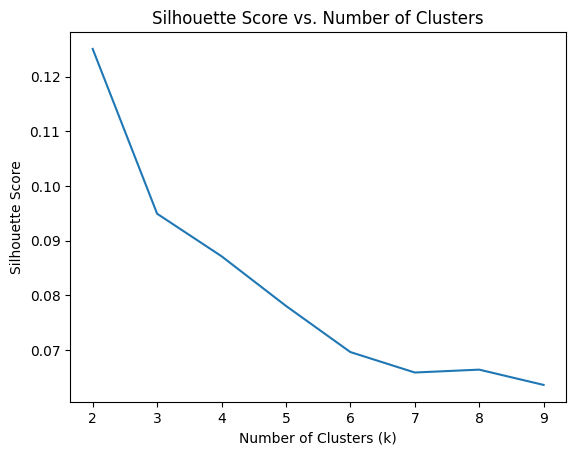

In [12]:
best_score = -1
best_k = 2
silhouette_scores = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    clusters = kmeans.fit_predict(item_data) # change here for either subscales or item-level
    score = silhouette_score(item_data, clusters) # change here for either subscales or item-level
    silhouette_scores.append(score)
    if score > best_score:
        best_k = k
        best_score = score

print(f"Best k: {best_k}")

# Plotting the silhouette scores
plt.plot(range(2, 10), silhouette_scores)
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt.show()

In [13]:
# determine optimal number of clusters using elbow method

best_score = -1
best_k = 2
for k in range(2,10):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    clusters = kmeans.fit_predict(item_data) # change here for either subscales or item-level
    score = silhouette_score(item_data, clusters) # change here for either subscales or item-level
    if score > best_score:
        best_k = k
        best_score = score

print(f"Best k: {best_k}")

Best k: 2


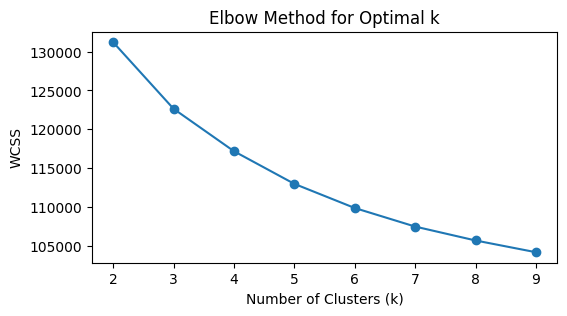

In [14]:
# visualize elbow plot

wcss = []  # Within-cluster sum of squares

for k in range(2, 10):  
    kmeans = KMeans(n_clusters=k, random_state = 42)
    clusters = kmeans.fit_predict(item_data) # change here for either subscales or item-level
    wcss.append(kmeans.inertia_)  

# Elbow plot
plt.figure(figsize=(6, 3))
plt.plot(range(2, 10), wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.show()

##### 2.2.2 - Clustering with k = 2

First we'll look at clustering with 2 groups. The below will show the mean positive, negative, and general subscale scores for each of the identified clusters in addition to a scatter plot showing the division of clusters just for positive and negative symptoms (primary symptoms of interest). 

In [15]:
# apply clustering with k = 2

kmeans = KMeans(n_clusters = 2, random_state = 42)
df_clean['symptom_cluster_k2'] = kmeans.fit_predict(item_data) # change here for either subscales or item-level

# analyze and visualize clusters

cluster_means = df_clean.groupby('symptom_cluster_k2')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                    panss_ptot  panss_ntot  panss_gtot
symptom_cluster_k2                                    
0                    26.682490   22.447471   48.538521
1                    19.418301   19.928105   35.697168


Just eyeballing, we can see that these two clusters differ primarily on positive symptoms and general symptoms with cluster 0 having lower levels of both, with similar levels of negative symptoms to cluster 1. 

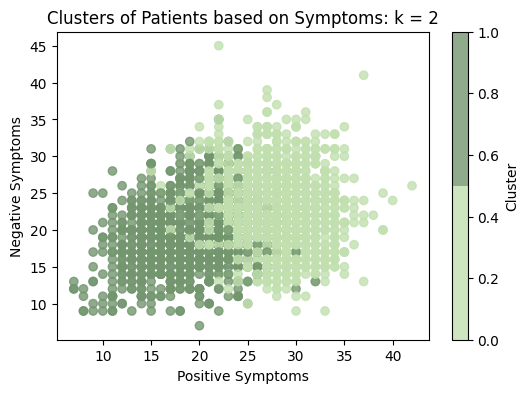

In [16]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean['panss_ptot'], df_clean['panss_ntot'], c=df_clean['symptom_cluster_k2'], cmap=cmap, alpha = 0.8)
plt.title('Clusters of Patients based on Symptoms: k = 2')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

##### 2.2.3 - Clustering with k = 3

Now we'll look at the same thing with 3 clusters instead of 2. 

In [17]:
# apply clustering with k = 3

kmeans = KMeans(n_clusters = 3, random_state = 42)
df_clean['symptom_cluster_k3'] = kmeans.fit_predict(item_data) # change here for either subscales or item-level

# analyze and visualize clusters

cluster_means = df_clean.groupby('symptom_cluster_k3')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                    panss_ptot  panss_ntot  panss_gtot
symptom_cluster_k3                                    
0                    24.880028   25.550459   48.205363
1                    27.622101   19.581855   47.136426
2                    18.387218   19.002820   34.295113


Again, just eyeballing, we can see that cluster 1 seems to have higher symptom severity overall whereas cluster 0 has moderate symptom levels and cluster 2 has the lowest symptom levels. 

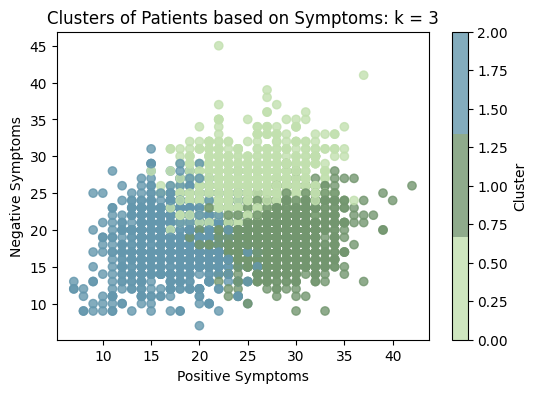

In [18]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f", "#6497ad"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean['panss_ptot'], df_clean['panss_ntot'], c=df_clean['symptom_cluster_k3'], cmap = cmap, alpha = 0.8)
plt.title('Clusters of Patients based on Symptoms: k = 3')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

##### 2.2.4 - Clustering with k = 4

Just to see how this solution does, testing the same as above with 4 clusters. 

In [19]:
# apply clustering with k = 4

kmeans = KMeans(n_clusters = 4, random_state = 42)
df_clean['symptom_cluster_k4'] = kmeans.fit_predict(item_data) # change here for either subscales or item-level

# analyze and visualize clusters

cluster_means = df_clean.groupby('symptom_cluster_k4')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                    panss_ptot  panss_ntot  panss_gtot
symptom_cluster_k4                                    
0                    25.103990   26.311971   46.360339
1                    24.666667   22.612930   48.146096
2                    17.753059   18.498331   33.458287
3                    28.363107   19.232039   46.735922


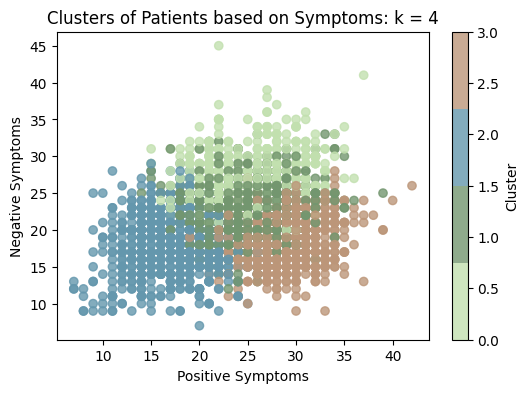

In [20]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f", "#6497ad", "#bc9679"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean['panss_ptot'], df_clean['panss_ntot'], c=df_clean['symptom_cluster_k4'], cmap=cmap, alpha = 0.8)
plt.title('Clusters of Patients based on Symptoms: k = 4')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

### 3 - Clustering based on speech characteristics

Now we will perform a similar clustering method using just select speech features and see how well these clusters map onto those defined by symptom levels. 

#### 3.1 - Prep data for clustering

In [21]:
pred_var = df_clean[['id', 'visit', 'speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness']]
     #  'first_person_percentage',
     #  'first_person_sentiment_positive', 'first_person_sentiment_negative',
     #  'first_person_sentiment_overall', 'word_repeat_percentage',
     #  'phrase_repeat_percentage',
     #  'word_coherence_mean', 'word_coherence_var', 'semantic_perplexity_mean',
     #  'semantic_perplexity_var', 'f0_mean', 'f0_stddev', 
     #  'loudness_mean', 'loudness_stddev', 'hnr_mean',
     #  'hnr_stddev', 'jitter', 'shimmer', 
     #  'gne_ratio', 'silence_ratio']]

In [22]:
pred_var.isnull().sum()

id                                     0
visit                                  0
speech_length_in_minutes_adjusted    468
speech_length_in_words_adjusted      524
mean_turn_length_in_minutes          619
mean_turn_length_in_words            640
speaker_percentage                   503
words_per_minute                     497
syllables_per_minute                 493
word_pause_length_mean               627
word_pause_variability               744
mean_pre_turn_pause                  641
positive_sentiment                   590
negative_sentiment                   565
lexical_richness                     632
dtype: int64

Remove NA values as this method does not handle missing data and scale as the speech features are measured on widely different scales. 

In [23]:
dhm_vars = pred_var.dropna()

In [24]:
# subset df_clean to match the subIDs and visits from dhm_vars

dhm_vars['combined_key'] = dhm_vars['id'].astype(str) + '_' + dhm_vars['visit'].astype(str)
df_clean['combined_key'] = df_clean['id'].astype(str) + '_' + df_clean['visit'].astype(str)

# Get the combined keys from dhm_vars
keys_to_keep = dhm_vars['combined_key'].values

# Subset df_clean based on the combined keys
df_clean_subset = df_clean[df_clean['combined_key'].isin(keys_to_keep)].copy()

# Optionally, drop the 'combined_key' columns if you don't need them anymore
dhm_vars.drop('combined_key', axis=1, inplace=True)
dhm_vars.drop('id', axis=1, inplace=True)
dhm_vars.drop('visit', axis=1, inplace=True)
df_clean_subset.drop('combined_key', axis=1, inplace=True) 

/tmp/ipykernel_13892/1857565005.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dhm_vars['combined_key'] = dhm_vars['id'].astype(str) + '_' + dhm_vars['visit'].astype(str)
/tmp/ipykernel_13892/1857565005.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dhm_vars.drop('combined_key', axis=1, inplace=True)
/tmp/ipykernel_13892/1857565005.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-

In [25]:
# preprocess and scale data 

scaler = StandardScaler()
scaled_dhms = scaler.fit_transform(dhm_vars)

#### 2.2 - Clustering

##### 2.2.1 - Elbow plot to determine optimal k

In [26]:
# determine optimal number of clusters using elbow method

best_score = -1
best_k = 2
for k in range(2,10):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    clusters = kmeans.fit_predict(scaled_dhms)
    score = silhouette_score(scaled_dhms, clusters)
    if score > best_score:
        best_k = k
        best_score = score

print(f"Best k: {best_k}")

Best k: 2


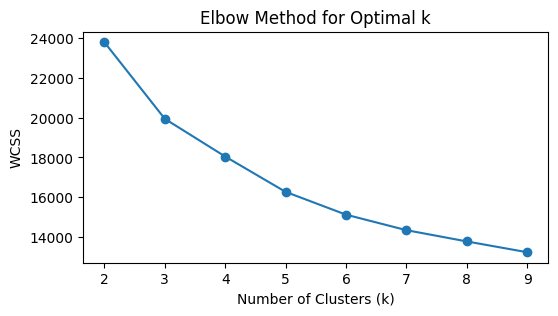

In [27]:
# visualize elbow plot

wcss = []  # Within-cluster sum of squares

for k in range(2, 10):  
    kmeans = KMeans(n_clusters=k, random_state = 42)
    clusters = kmeans.fit_predict(scaled_dhms)
    wcss.append(kmeans.inertia_)  

# Elbow plot
plt.figure(figsize=(6, 3))
plt.plot(range(2, 10), wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.show()

##### 3.2.2 - Clustering with k = 2

In [28]:
# apply clustering with k = 2

kmeans = KMeans(n_clusters = 2, random_state = 42)
df_clean_subset['dhm_cluster_k2'] = kmeans.fit_predict(scaled_dhms)

# analyze and visualize clusters

cluster_means = df_clean_subset.groupby('dhm_cluster_k2')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                panss_ptot  panss_ntot  panss_gtot
dhm_cluster_k2                                    
0                25.277082   20.452469   44.960943
1                22.838146   21.886778   42.412614


Based on the 2 cluster solution, we see that cluster 0 has overall higher positive symptoms and general symptoms but slightly lower negative symptoms. This is not the same pattern as the clusters identified based only on symptom levels. 

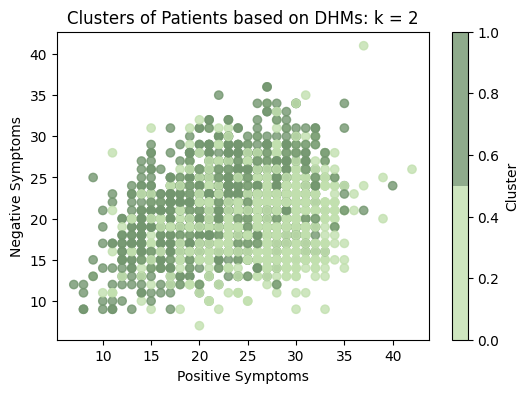

In [29]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean_subset['panss_ptot'], df_clean_subset['panss_ntot'], c=df_clean_subset['dhm_cluster_k2'], cmap=cmap, alpha = 0.8)
plt.title('Clusters of Patients based on DHMs: k = 2')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

##### 3.2.3 - Clustering with k = 3

In [30]:
# apply clustering with k = 3

kmeans = KMeans(n_clusters = 3, random_state = 42)
df_clean_subset['dhm_cluster_k3'] = kmeans.fit_predict(scaled_dhms)

# analyze and visualize clusters

cluster_means = df_clean_subset.groupby('dhm_cluster_k3')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                panss_ptot  panss_ntot  panss_gtot
dhm_cluster_k3                                    
0                25.423673   20.348451   45.126106
1                23.930283   21.198257   43.523965
2                22.802585   21.976498   42.394830


Here we see again that cluster 0 showes the highest level of positive symptoms compared to cluster 1 and then cluster 2, while clusters differ only slightly on negative and general symptoms. 

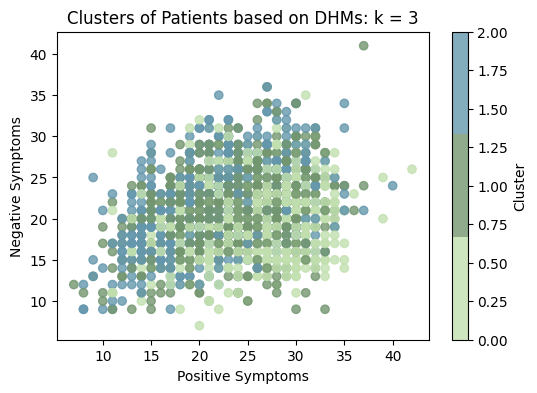

In [31]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f", "#6497ad"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean_subset['panss_ptot'], df_clean_subset['panss_ntot'], c=df_clean_subset['dhm_cluster_k3'], cmap = cmap, alpha = 0.8)
plt.title('Clusters of Patients based on DHMs: k = 3')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

##### 3.2.4 - Clustering with k = 4

In [32]:
# apply clustering with k = 4

kmeans = KMeans(n_clusters = 4, random_state = 42)
df_clean_subset['dhm_cluster_k4'] = kmeans.fit_predict(scaled_dhms)

# analyze and visualize clusters

cluster_means = df_clean_subset.groupby('dhm_cluster_k4')[['panss_ptot', 'panss_ntot', 'panss_gtot']].mean()
print(cluster_means)

                panss_ptot  panss_ntot  panss_gtot
dhm_cluster_k4                                    
0                25.634812   20.174061   45.409556
1                22.026101   21.642741   41.318108
2                23.284603   22.185070   43.161742
3                25.102286   20.701564   44.688327


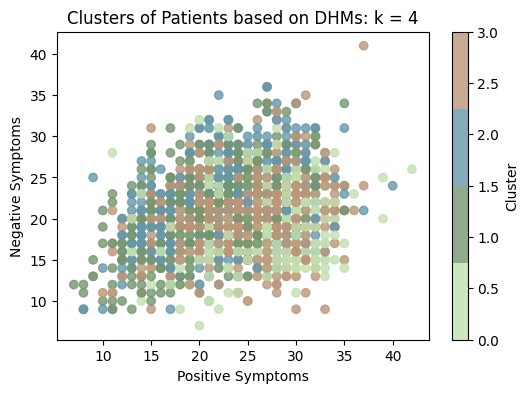

In [33]:
# Visualize the clusters with a scatter plot

colors = ["#c2e0af", "#73966f", "#6497ad", "#bc9679"]
cmap = ListedColormap(colors)

plt.figure(figsize=(6, 4))
plt.scatter(df_clean_subset['panss_ptot'], df_clean_subset['panss_ntot'], c=df_clean_subset['dhm_cluster_k4'], cmap=cmap, alpha = 0.8)
plt.title('Clusters of Patients based on DHMs: k = 4')
plt.xlabel('Positive Symptoms')
plt.ylabel('Negative Symptoms')
plt.colorbar(label='Cluster') 
plt.show()

### 3 - Examine clusters longitudinally

As we so far have used data from the entire study to identify clusters, we will next examine how these clusters change in symptom levels over the course of the study. We will look at this first with the three cluster solution.

In [34]:
# map visits

map_visit_names(df_clean_subset)

# Create a list of visit names in the desired order
visit_order = ['SCR', 'BL', 'V6', 'V7', 'V8', 'EOT', 'SF'] 

# Convert 'visit_name' to an ordered categorical
df_clean_subset['visit_name'] = pd.Categorical(df_clean_subset['visit_name'], categories=visit_order, ordered=True)

# remove SF
df_clean_subset = df_clean_subset[df_clean_subset['visit_name'] != 'SF'].copy()

#### 3.1 - Symptom-based clusters

The following line graphs show how PANSS overall, PANSS-P and PANSS-N scores for each of the clusters as identified based on symptom domains changes over time using both k = 2 and k = 3.

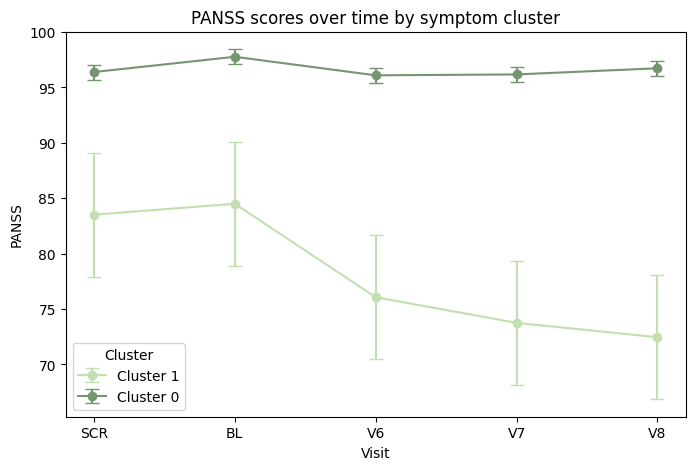

In [35]:
# create line graph showing trajectory of symptoms for each symptom-based cluster 
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['symptom_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['symptom_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss'], 
        yerr=cluster_data['panss'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS scores over time by symptom cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS')
plt.legend(title='Cluster')
plt.show()

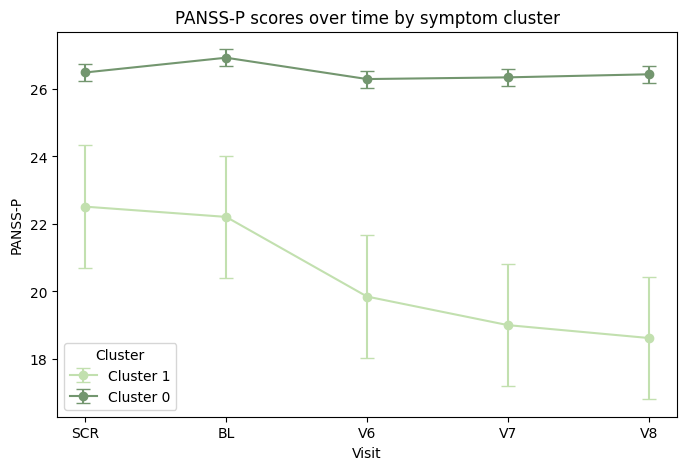

In [36]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['symptom_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['symptom_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss_ptot'], 
        yerr=cluster_data['panss_ptot'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS-P scores over time by symptom cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS-P')
plt.legend(title='Cluster')
plt.show()

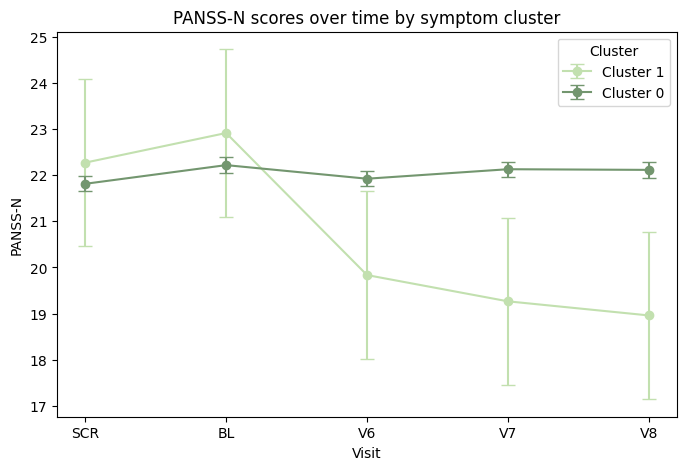

In [37]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['symptom_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['symptom_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss_ntot'], 
        yerr=cluster_data['panss_ntot'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS-N scores over time by symptom cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS-N')
plt.legend(title='Cluster')
plt.show()

#### 3.2 - DHM-based clusters

This line graph shows how PANSS overall scores for each of the clusters as identified based on speech characteristics changes over time.  

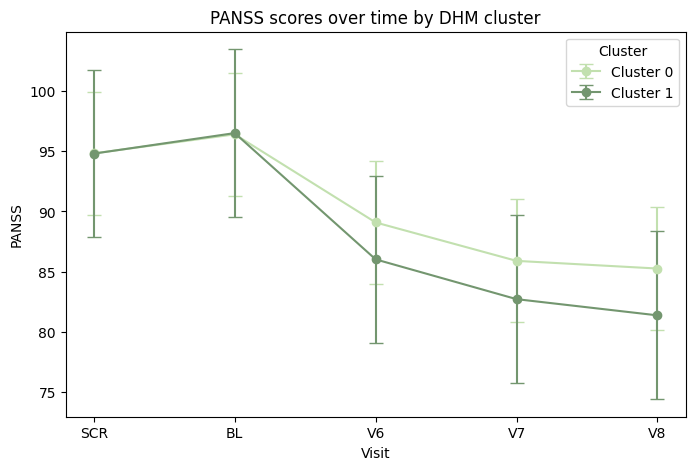

In [38]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['dhm_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['dhm_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss'], 
        yerr=cluster_data['panss'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS scores over time by DHM cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS')
plt.legend(title='Cluster')
plt.show()

Not accounting for treatment group just yet, we don't see great separation between groups the way we do with the symptom-based clustering. 

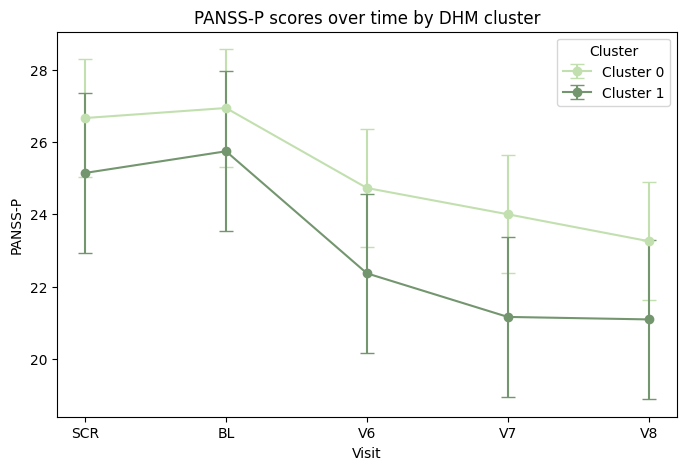

In [39]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['dhm_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['dhm_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss_ptot'], 
        yerr=cluster_data['panss_ptot'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS-P scores over time by DHM cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS-P')
plt.legend(title='Cluster')
plt.show()

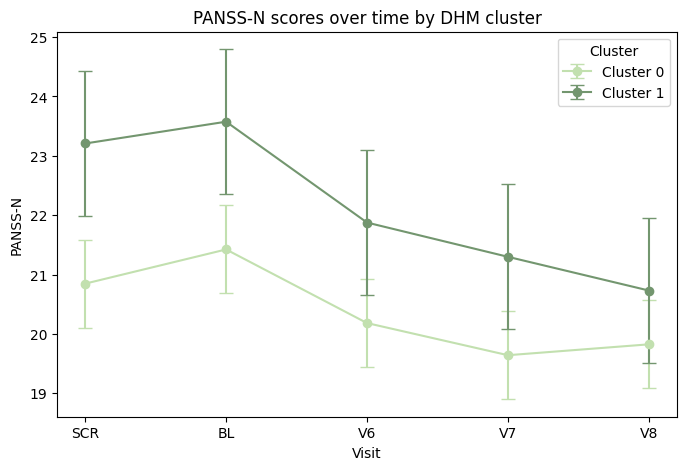

In [40]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

plt.figure(figsize=(8,5))

# Get unique cluster labels
clusters = df_clean_subset['dhm_cluster_k2'].unique()

for i, cluster in enumerate(clusters):
    cluster_data = cluster_means[cluster_means['dhm_cluster_k2'] == cluster]
    plt.errorbar(
        cluster_data['visit_name'], 
        cluster_data['panss_ntot'], 
        yerr=cluster_data['panss_ntot'].std(), 
        marker='o', 
        linestyle='-',
        label=f"Cluster {cluster}",
        capsize=5,
        color=palette[i]  # Use colors from the palette
    )

plt.title('PANSS-N scores over time by DHM cluster')
plt.xlabel('Visit')
plt.ylabel('PANSS-N')
plt.legend(title='Cluster')
plt.show()

### 4 - Response to treatment

Here, we will determine whether clusters identified by both symptoms and DHMs respond differently to treatment. 

In [41]:
df_clean_subset = df_clean_subset[df_clean_subset['arm'].isin([1, 0])].copy()

#### 4.1 - PANSS Overall

In [42]:
cluster_1_sym = df_clean_subset[df_clean_subset['symptom_cluster_k2'] == 1]
cluster_0_sym = df_clean_subset[df_clean_subset['symptom_cluster_k2'] == 0]
cluster_1_dhm = df_clean_subset[df_clean_subset['dhm_cluster_k2'] == 1]
cluster_0_dhm = df_clean_subset[df_clean_subset['dhm_cluster_k2'] == 0]

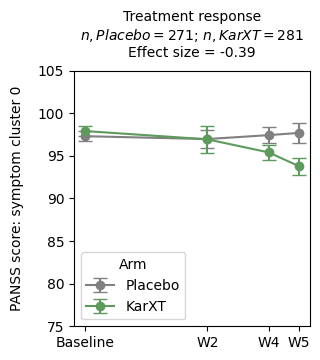

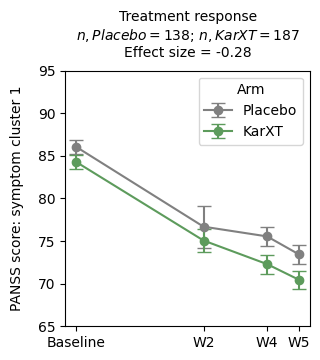

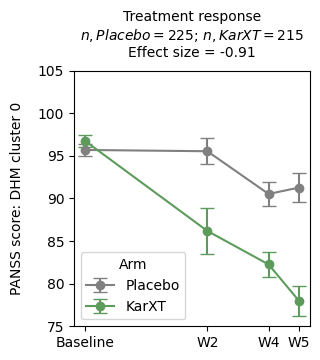

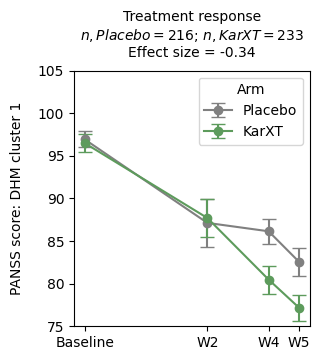

In [43]:
response_to_treatment(cluster_0_sym, 'panss', 'PANSS score: symptom cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_sym, 'panss', 'PANSS score: symptom cluster 1', min_y=65, max_y=95, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_0_dhm, 'panss', 'PANSS score: DHM cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_dhm, 'panss', 'PANSS score: DHM cluster 1', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)

#### 4.2 - PANSS-P

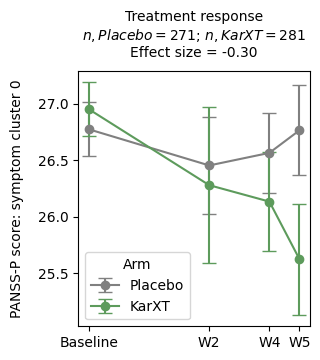

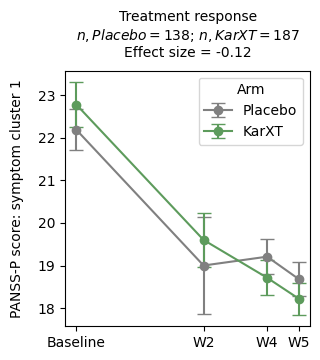

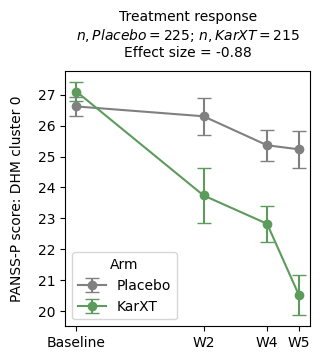

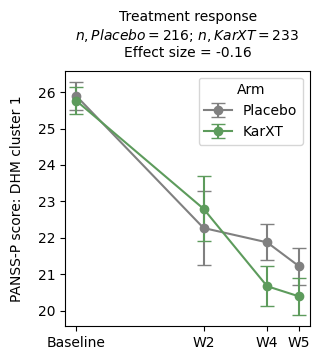

In [44]:
response_to_treatment(cluster_0_sym, 'panss_ptot', 'PANSS-P score: symptom cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_sym, 'panss_ptot', 'PANSS-P score: symptom cluster 1', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_0_dhm, 'panss_ptot', 'PANSS-P score: DHM cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_dhm, 'panss_ptot', 'PANSS-P score: DHM cluster 1', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)

#### 4.3 - PANSS-N

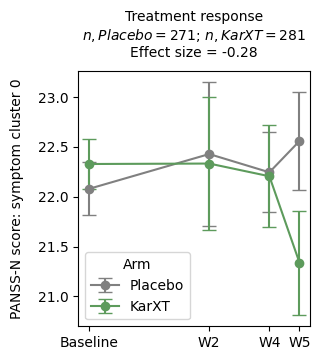

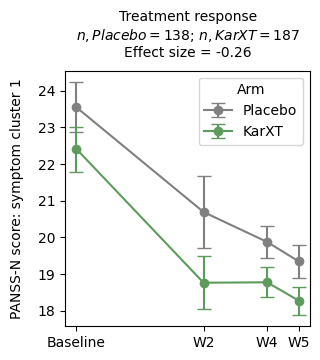

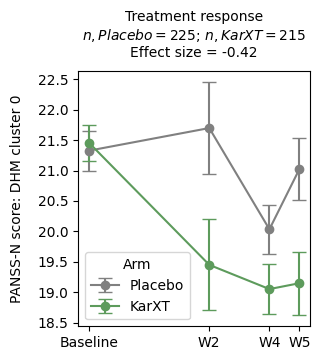

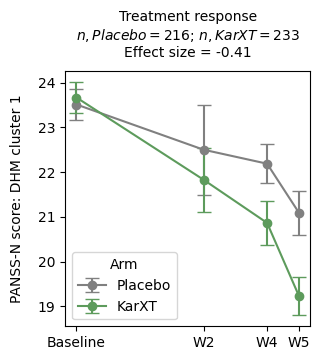

In [45]:
response_to_treatment(cluster_0_sym, 'panss_ntot', 'PANSS-N score: symptom cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_sym, 'panss_ntot', 'PANSS-N score: symptom cluster 1', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_0_dhm, 'panss_ntot', 'PANSS-N score: DHM cluster 0', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)
response_to_treatment(cluster_1_dhm, 'panss_ntot', 'PANSS-N score: DHM cluster 1', min_y=None, max_y=None, fontsize=10, dpi=100, filename=None)

### __OLD GRAPHS__

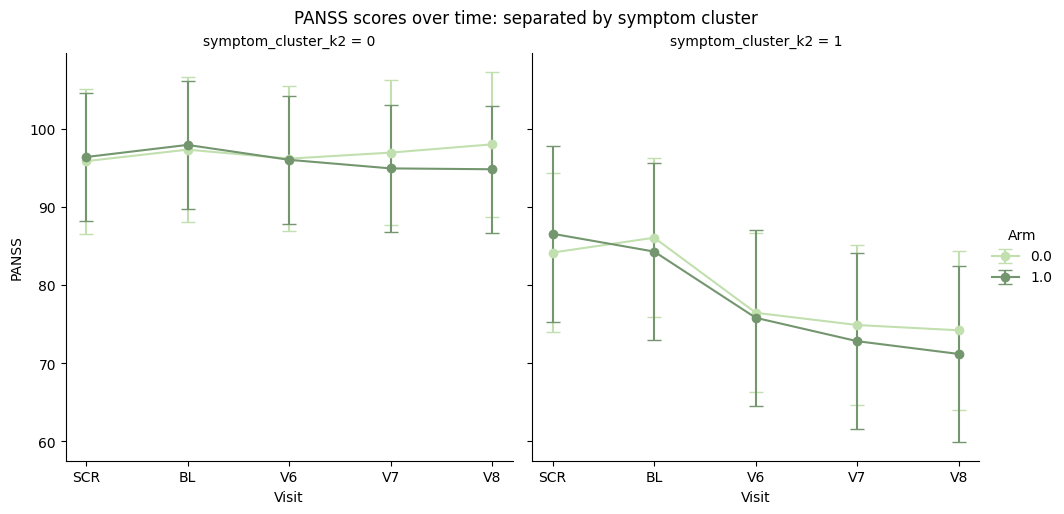

In [46]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='symptom_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss') 

g.set_axis_labels('Visit', 'PANSS')
g.add_legend(title='Arm')
g.fig.suptitle('PANSS scores over time: separated by symptom cluster', y=1.02)
plt.show()

**NB the error bars are acting strange for the BL visit for cluster 2 placebo group (not sure why it is detecting missing data) so will leave error bars off for now for remaining plots. 

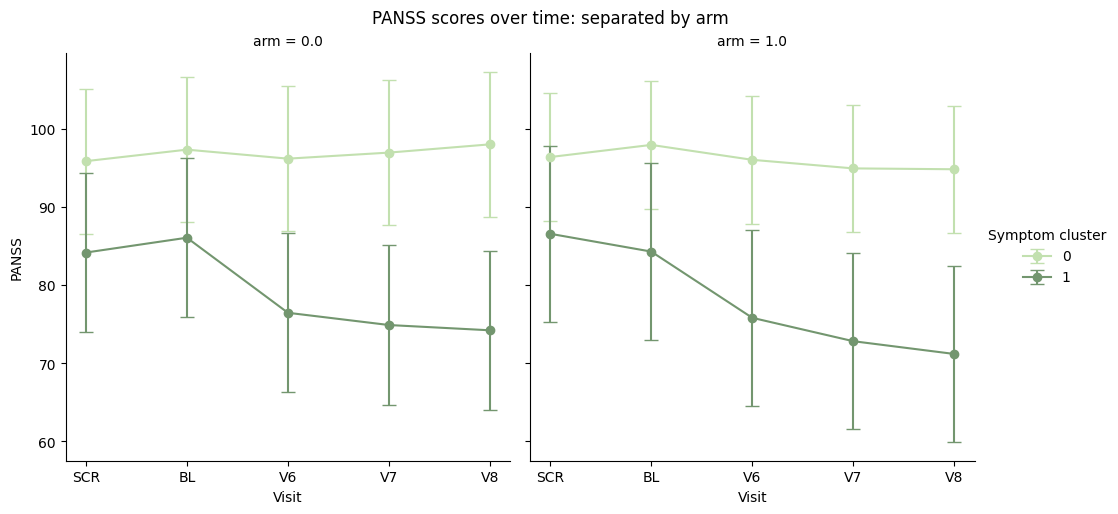

In [47]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='symptom_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss') 

g.set_axis_labels('Visit', 'PANSS')
g.add_legend(title='Symptom cluster')
g.fig.suptitle('PANSS scores over time: separated by arm', y=1.02)
plt.show()

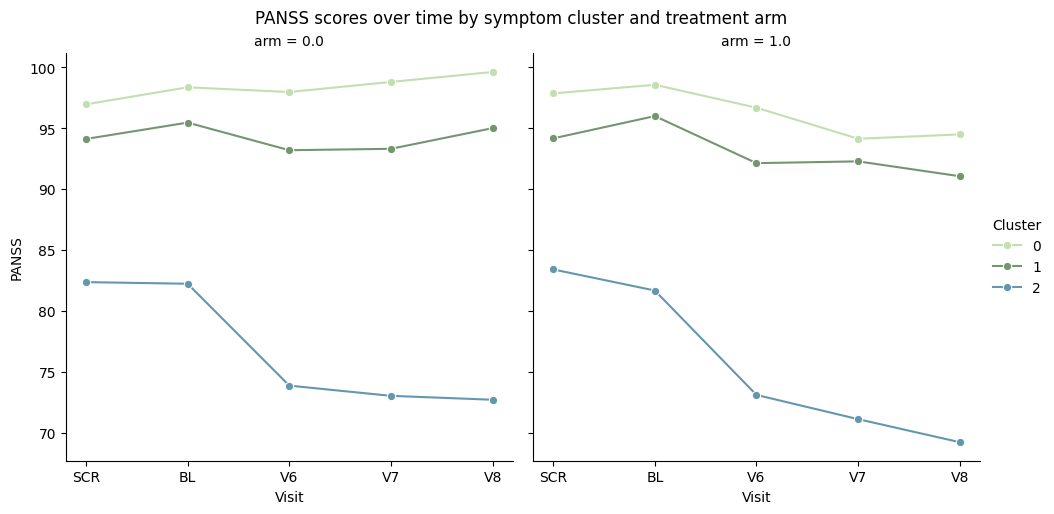

In [48]:
# create line graph showing trajectory of symptoms for each DHM-based cluster 
cluster_means = df_clean_subset.groupby(['symptom_cluster_k3', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

g = sns.FacetGrid(cluster_means, col='arm', hue='symptom_cluster_k3', palette=palette, height=5)
g.map(sns.lineplot, 'visit_name', 'panss', marker='o')
g.set_axis_labels('Visit', 'PANSS')
g.add_legend(title='Cluster')
g.fig.suptitle('PANSS scores over time by symptom cluster and treatment arm', y=1.02)
plt.show()

This graph is interesting in and of itself, indicating some interesting patterns related to treatment response. No DHMs involved here. But, we see that there may be some placebo responders that have overall lower levels of PANSS symptoms at the beginning of the study. 

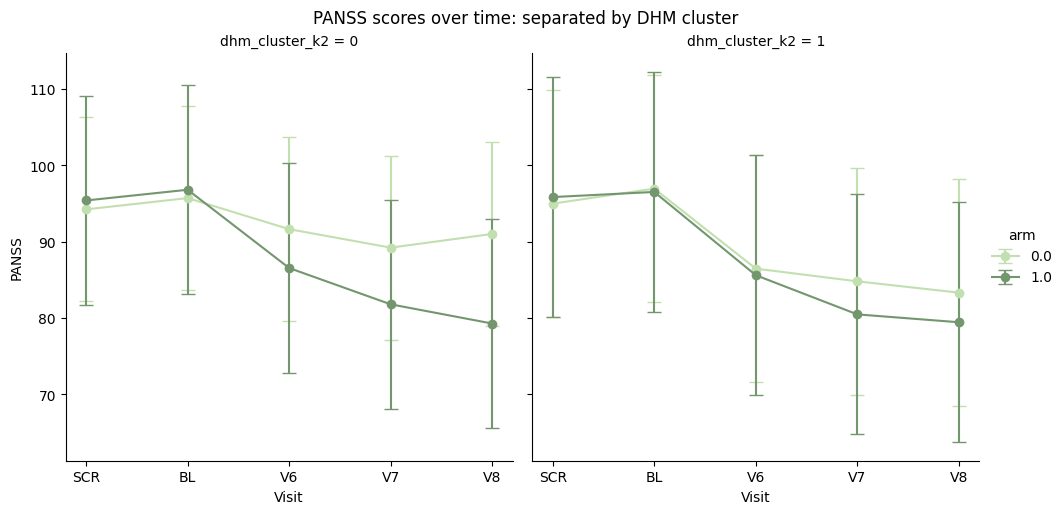

In [49]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='dhm_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss') 

g.set_axis_labels('Visit', 'PANSS')
g.add_legend(title='arm')
g.fig.suptitle('PANSS scores over time: separated by DHM cluster', y=1.02)
plt.show()

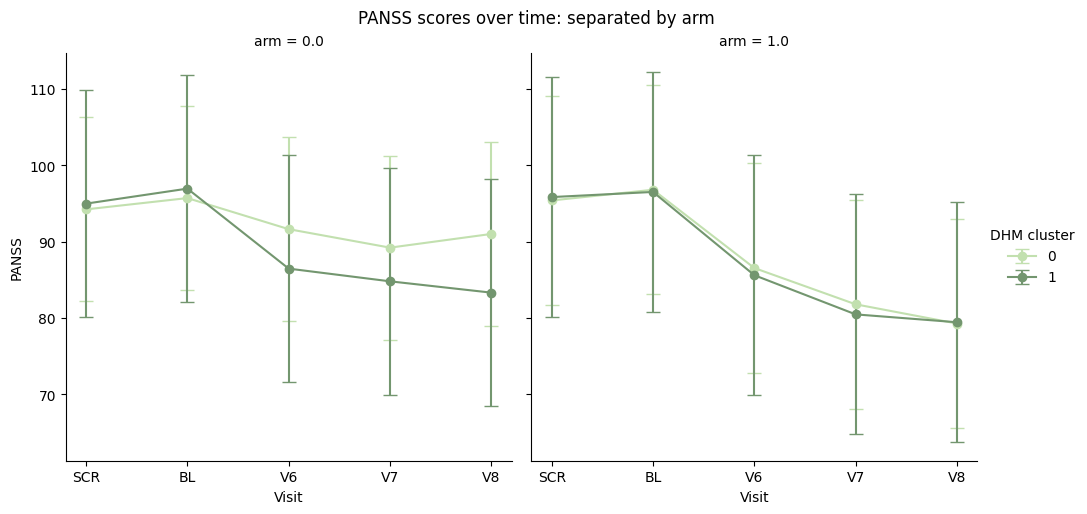

In [50]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='dhm_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss') 

g.set_axis_labels('Visit', 'PANSS')
g.add_legend(title='DHM cluster')
g.fig.suptitle('PANSS scores over time: separated by arm', y=1.02)
plt.show()

Here we see that the DHM clusters might separate out some placebo responders, but overall don't show any distinct patterns for KarXT response. 

#### 4.2 - PANSS-P

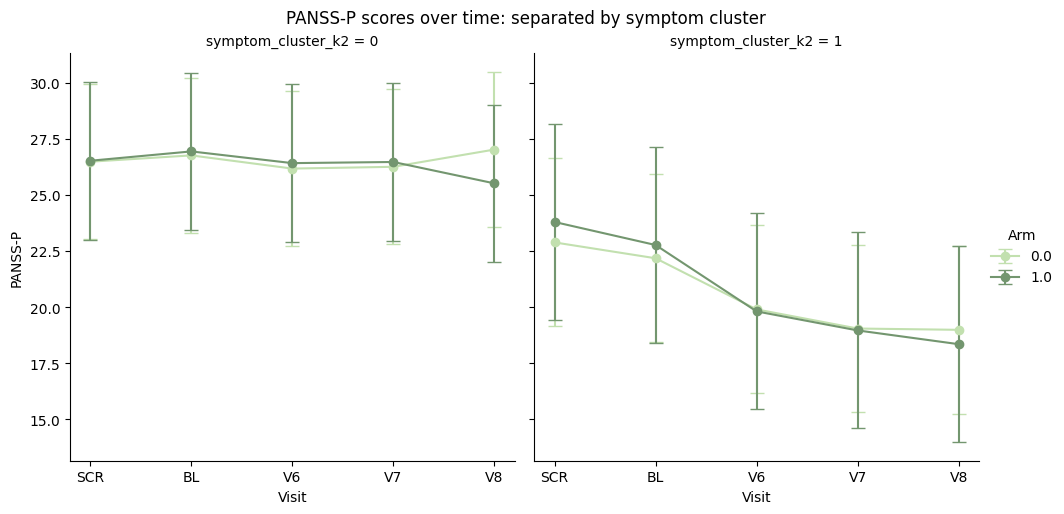

In [51]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='symptom_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ptot') 

g.set_axis_labels('Visit', 'PANSS-P')
g.add_legend(title='Arm')
g.fig.suptitle('PANSS-P scores over time: separated by symptom cluster', y=1.02)
plt.show()

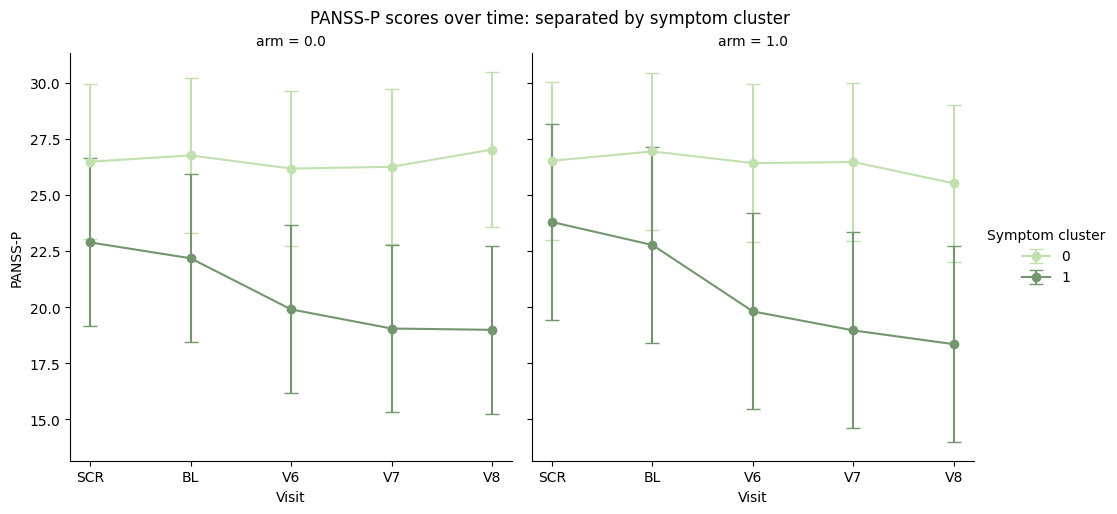

In [52]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='symptom_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ptot') 

g.set_axis_labels('Visit', 'PANSS-P')
g.add_legend(title='Symptom cluster')
g.fig.suptitle('PANSS-P scores over time: separated by symptom cluster', y=1.02)
plt.show()

More indication of potential placebo responders as identified by DHM clusters, specifically related to positive symptom score change. 

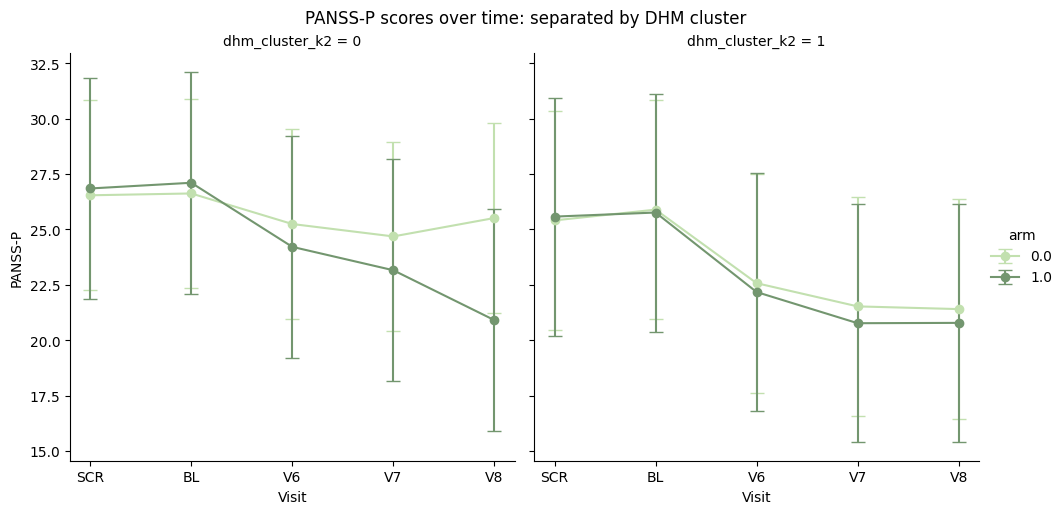

In [53]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='dhm_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ptot') 

g.set_axis_labels('Visit', 'PANSS-P')
g.add_legend(title='arm')
g.fig.suptitle('PANSS-P scores over time: separated by DHM cluster', y=1.02)
plt.show()

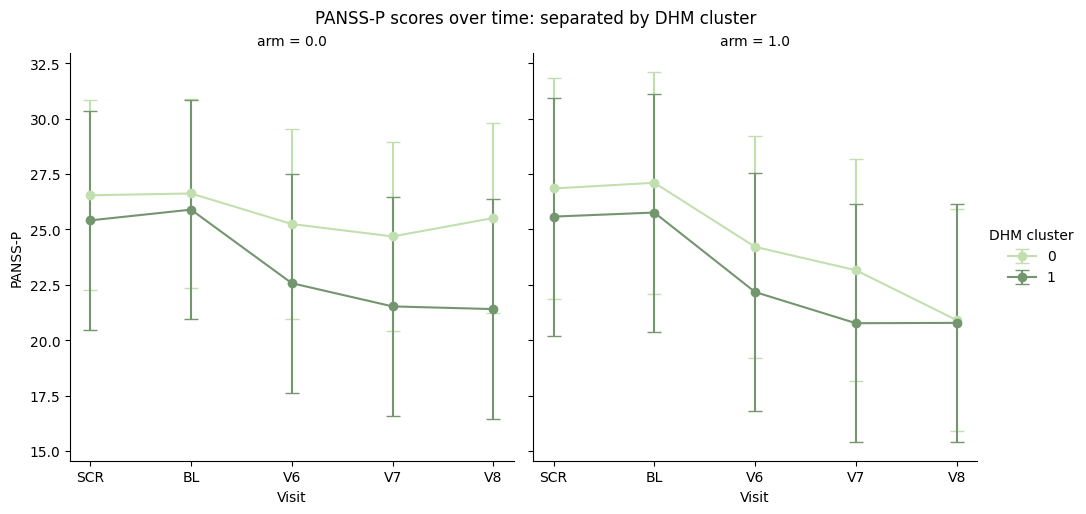

In [54]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='dhm_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ptot') 

g.set_axis_labels('Visit', 'PANSS-P')
g.add_legend(title='DHM cluster')
g.fig.suptitle('PANSS-P scores over time: separated by DHM cluster', y=1.02)
plt.show()

#### 4.3 - PANSS-N

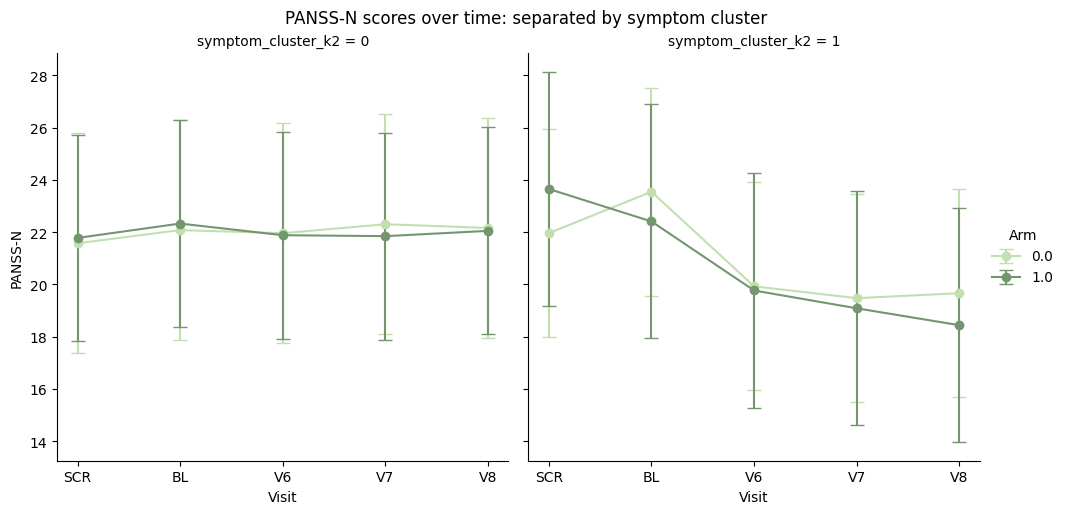

In [55]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='symptom_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ntot') 

g.set_axis_labels('Visit', 'PANSS-N')
g.add_legend(title='Arm')
g.fig.suptitle('PANSS-N scores over time: separated by symptom cluster', y=1.02)
plt.show()

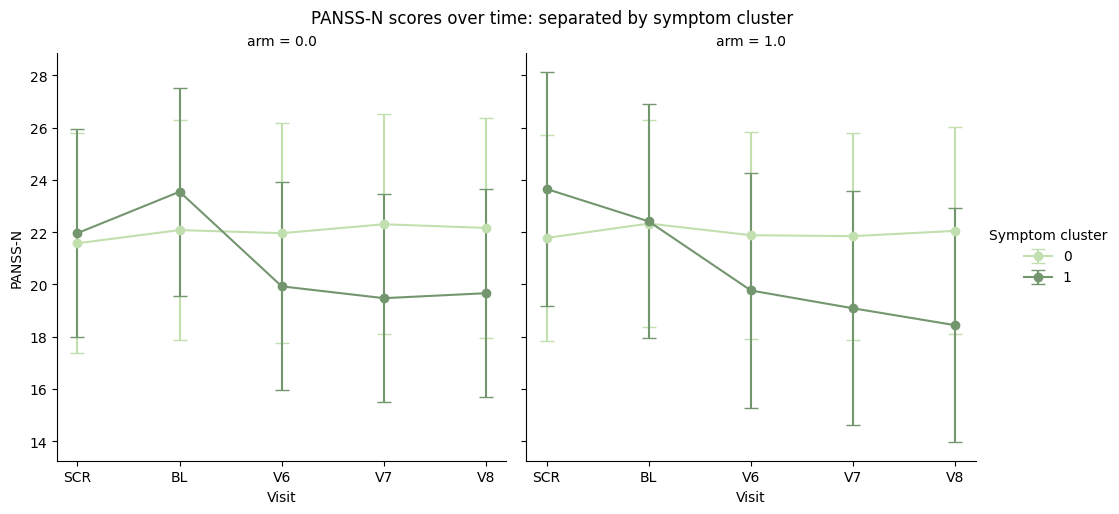

In [56]:
cluster_means = df_clean_subset.groupby(['symptom_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='symptom_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['symptom_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['symptom_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ntot') 

g.set_axis_labels('Visit', 'PANSS-N')
g.add_legend(title='Symptom cluster')
g.fig.suptitle('PANSS-N scores over time: separated by symptom cluster', y=1.02)
plt.show()

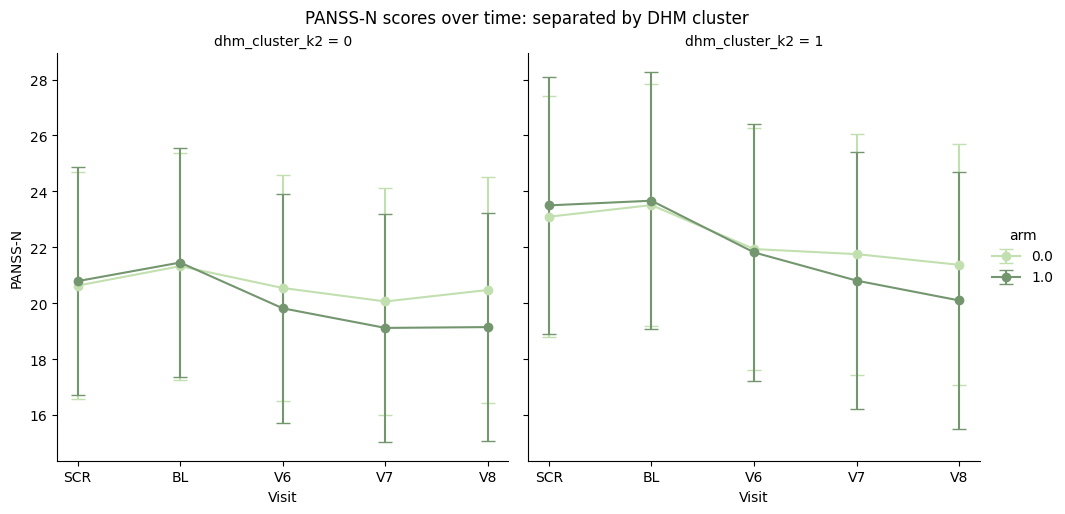

In [57]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='dhm_cluster_k2', hue='arm', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ntot') 

g.set_axis_labels('Visit', 'PANSS-N')
g.add_legend(title='arm')
g.fig.suptitle('PANSS-N scores over time: separated by DHM cluster', y=1.02)
plt.show()

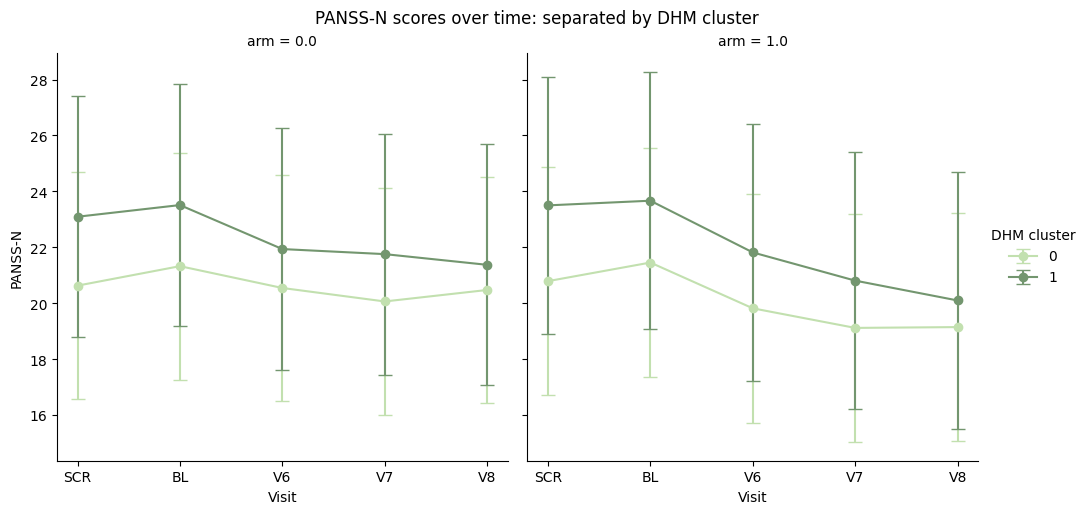

In [58]:
cluster_means = df_clean_subset.groupby(['dhm_cluster_k2', 'visit_name', 'arm'])[['panss', 'panss_ptot', 'panss_ntot']].mean().reset_index()

palette = ["#c2e0af", "#73966f", "#6497ad"]

# Create a FacetGrid with 'arm' as the column
g = sns.FacetGrid(cluster_means, col='arm', hue='dhm_cluster_k2', palette=palette, height=5)

# Map the errorbar plot to each facet 
def plot_with_errorbars(x, y, **kwargs):
    data = kwargs.pop('data')
    cluster = data['dhm_cluster_k2'].values[0]
    arm = data['arm'].values[0]
    
    # Filter x to match the visit_names in the current group
    x = data['visit_name']
    
    std_dev = df_clean_subset[
        (df_clean_subset['dhm_cluster_k2'] == cluster) &
        (df_clean_subset['arm'] == arm)
    ][y].std()

    plt.errorbar(x, data[y], yerr=std_dev, fmt='o-', capsize=5, **kwargs)

g.map_dataframe(plot_with_errorbars, 'visit_name', 'panss_ntot') 

g.set_axis_labels('Visit', 'PANSS-N')
g.add_legend(title='DHM cluster')
g.fig.suptitle('PANSS-N scores over time: separated by DHM cluster', y=1.02)
plt.show()

### 5 - Understanding important features within clusters

#### 5.1 - Centroid centers and center differences

In [59]:
# Analyze Cluster Centers
kmeans = KMeans(n_clusters = 3, random_state = 42) # Assuming 3 clusters
kmeans.fit(scaled_dhms) 
centroids = kmeans.cluster_centers_

# Create a DataFrame for the centroids
centroid_df = pd.DataFrame(centroids, columns = dhm_vars.columns)  # Assuming df is your original DataFrame
centroid_df

,speech_length_in_minutes_adjusted,speech_length_in_words_adjusted,mean_turn_length_in_minutes,mean_turn_length_in_words,speaker_percentage,words_per_minute,syllables_per_minute,word_pause_length_mean,word_pause_variability,mean_pre_turn_pause,positive_sentiment,negative_sentiment,lexical_richness
0,1.063583,1.074860,0.981451,1.063746,1.069625,0.326440,0.372078,-0.449743,-0.252643,0.026017,-0.277680,-0.042690,-0.813013
1,-0.504877,-0.288631,-0.578621,-0.374326,-0.294045,0.610797,0.576304,-0.598422,-0.555663,-0.359510,-0.246859,0.234545,0.133465
2,-0.585196,-0.830447,-0.418399,-0.726198,-0.819046,-1.005657,-1.016928,1.123290,0.867789,0.360178,0.561269,-0.207663,0.719674


In [60]:
# Calculate the differences between centroids
centroid_diff = centroid_df.diff(axis=0)
centroid_diff

,speech_length_in_minutes_adjusted,speech_length_in_words_adjusted,mean_turn_length_in_minutes,mean_turn_length_in_words,speaker_percentage,words_per_minute,syllables_per_minute,word_pause_length_mean,word_pause_variability,mean_pre_turn_pause,positive_sentiment,negative_sentiment,lexical_richness
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1.568460,-1.363492,-1.560072,-1.438072,-1.363670,0.284357,0.204225,-0.148679,-0.303020,-0.385527,0.030821,0.277235,0.946478
2,-0.080319,-0.541815,0.160222,-0.351872,-0.525001,-1.616454,-1.593232,1.721712,1.423452,0.719688,0.808128,-0.442209,0.586208


In [61]:
# Analyze Cluster Centers
kmeans = KMeans(n_clusters = 2, random_state = 42) # Assuming 3 clusters
kmeans.fit(scaled_dhms) 
centroids = kmeans.cluster_centers_

# Create a DataFrame for the centroids
centroid_df = pd.DataFrame(centroids, columns = dhm_vars.columns)  # Assuming df is your original DataFrame
centroid_df

,speech_length_in_minutes_adjusted,speech_length_in_words_adjusted,mean_turn_length_in_minutes,mean_turn_length_in_words,speaker_percentage,words_per_minute,syllables_per_minute,word_pause_length_mean,word_pause_variability,mean_pre_turn_pause,positive_sentiment,negative_sentiment,lexical_richness
0,0.644587,0.754150,0.545202,0.702240,0.748480,0.534090,0.572668,-0.580378,-0.376276,-0.055687,-0.342136,0.072655,-0.657960
1,-0.663675,-0.776483,-0.561347,-0.723035,-0.770645,-0.549906,-0.589627,0.597565,0.387418,0.057336,0.352267,-0.074807,0.677444


In [62]:
# Calculate the differences between centroids
centroid_diff = centroid_df.diff(axis=0)
centroid_diff

,speech_length_in_minutes_adjusted,speech_length_in_words_adjusted,mean_turn_length_in_minutes,mean_turn_length_in_words,speaker_percentage,words_per_minute,syllables_per_minute,word_pause_length_mean,word_pause_variability,mean_pre_turn_pause,positive_sentiment,negative_sentiment,lexical_richness
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-1.308261,-1.530633,-1.106549,-1.425275,-1.519125,-1.083995,-1.162295,1.177943,0.763694,0.113023,0.694403,-0.147462,1.335404


#### 5.2 - Radar charts to visualize select speech features differences

In [63]:
def radar_chart(df, cluster_labels, features, filename, colors=None): 
    """
    Creates a radar chart to visualize feature contributions to clusters.
    """
    num_clusters = len(df[cluster_labels].unique())
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False)

    # Standardize the data
    scaler = StandardScaler()
    df_scaled = df.copy()
    df_scaled[features] = scaler.fit_transform(df_scaled[features])

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.yaxis.grid(False)  

    # If no colors are provided, use default colors
    if colors is None:
        colors = plt.rcParams['axes.prop_cycle'].by_key()['color'][:num_clusters] 

    for i in range(num_clusters):
        values = df_scaled[df_scaled[cluster_labels] == i][features].mean().values.flatten().tolist()
        ax.plot(angles, values, linewidth=1, linestyle='solid', label=f"Cluster {i}", color=colors[i])
        ax.fill(angles, values, alpha=0.25, color=colors[i])

    ax.set_xticks(angles)
    ax.set_xticklabels(features)

    ax.set_title("Feature contributions to identified clusters")
    plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
    plt.tight_layout()
    
    if filename:
        fig.savefig(filename)
        plt.close(fig)
    else:
        plt.show()

##### 5.2.1 - Radar chart based on symptom clusters

In [64]:
# Radar charts - select features

colors = ["#c2e0af", "#73966f", "#6497ad"]
radar_features = ['speech_length_in_minutes_adjusted',
       'speech_length_in_words_adjusted',
       'mean_turn_length_in_minutes', 'mean_turn_length_in_words',
       'speaker_percentage',
       'words_per_minute', 'syllables_per_minute',
       'word_pause_length_mean', 'word_pause_variability',
       'mean_pre_turn_pause', 'positive_sentiment', 'negative_sentiment',
       'lexical_richness']
symptom_features = ['panss_p1', 'panss_p2', 'panss_p3',
 'panss_p4', 'panss_p5', 'panss_p6', 'panss_p7', 'panss_n1',
 'panss_n2', 'panss_n3', 'panss_n4', 'panss_n5', 'panss_n6',
 'panss_n7', 'panss_g1', 'panss_g2', 'panss_g3', 'panss_g4',
 'panss_g5', 'panss_g6', 'panss_g7', 'panss_g8', 'panss_g9',
 'panss_g10', 'panss_g11', 'panss_g12', 'panss_g13', 'panss_g14',
 'panss_g15', 'panss_g16']

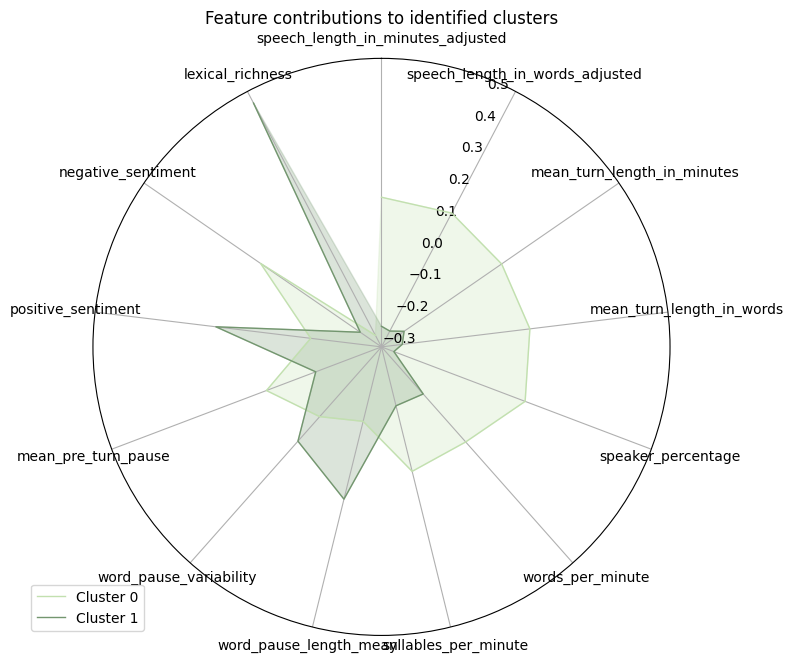

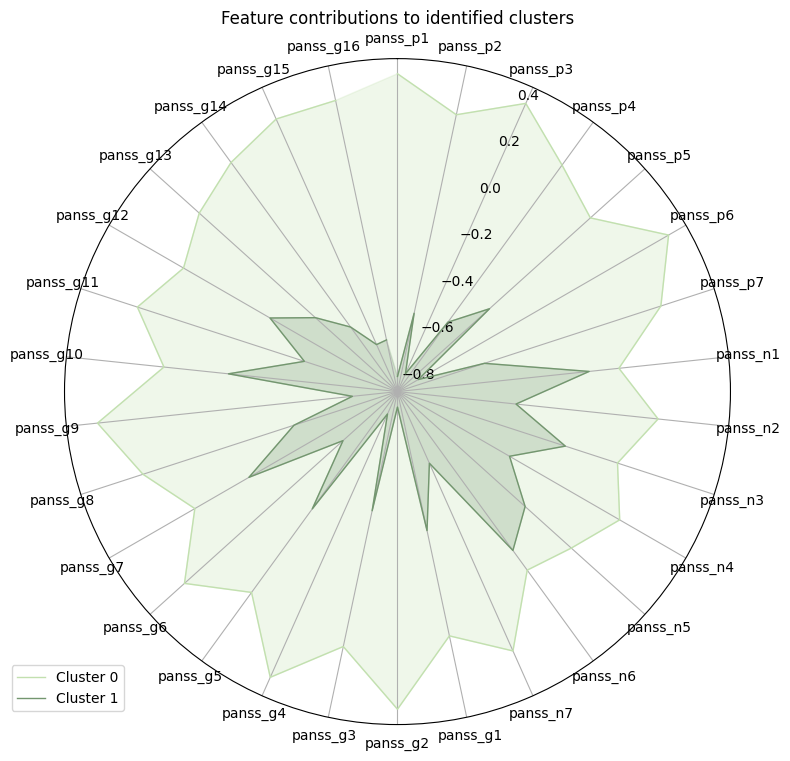

In [65]:
# Build charts based on symptom clusters

radar_chart(df_clean_subset, 'symptom_cluster_k2', radar_features, colors = colors, filename = (figure_dir+f"5.2_dhm_radar.png"))
radar_chart(df_clean_subset, 'symptom_cluster_k2', radar_features, colors = colors, filename = None)

radar_chart(df_clean_subset, 'symptom_cluster_k2', symptom_features, colors = colors, filename = (figure_dir+f"5.2_symptom_radar.png"))
radar_chart(df_clean_subset, 'symptom_cluster_k2', symptom_features, colors = colors, filename = None)

Here, we start to see how DHMs might define different clinical presentations. In section 4.3 above, we started to see that __cluster 1__ might correspond with more severe negative symptoms that see improvement over time with treatment. In the radar graph here (and below) we see that this group has higher lexical richness, higher positive sentiment, slower rate of speech, and high word pause mean and variability. 

##### 5.2.2 - Radar chart based on DHM clusters

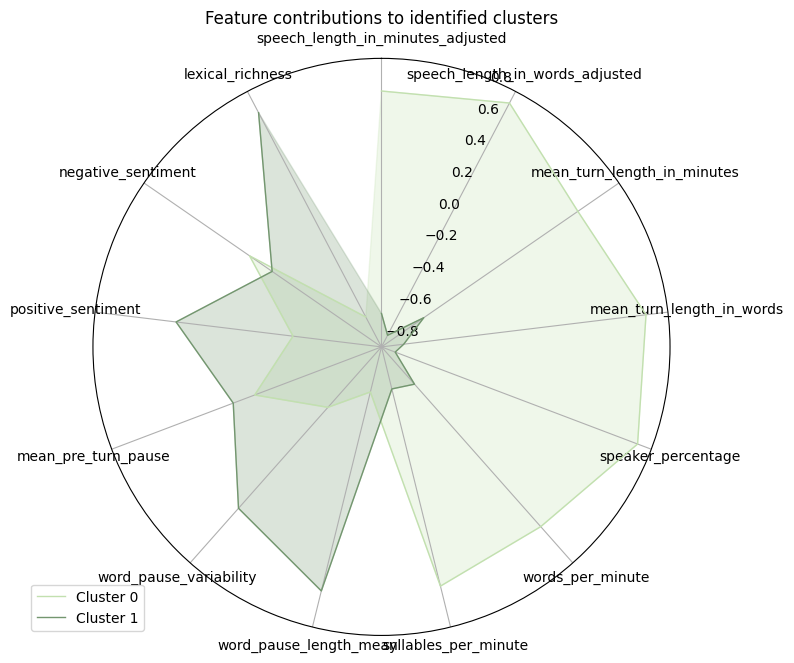

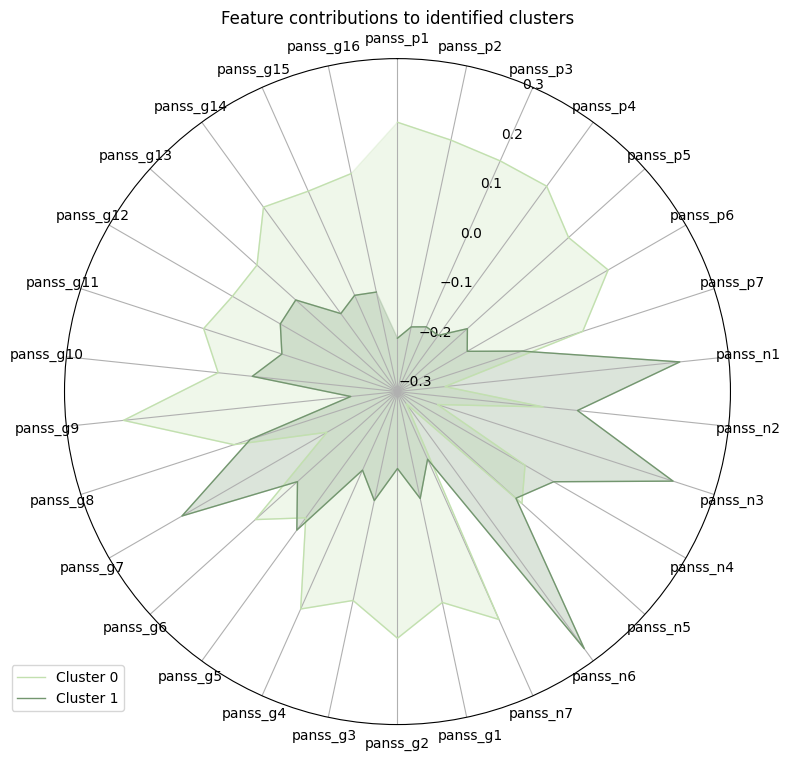

In [66]:
# Build charts based on DHM clusters 

radar_chart(df_clean_subset, 'dhm_cluster_k2', radar_features, colors = colors, filename = (figure_dir+f"5.2_dhm_dhm_radar.png"))
radar_chart(df_clean_subset, 'dhm_cluster_k2', radar_features, colors = colors, filename = None)

radar_chart(df_clean_subset, 'dhm_cluster_k2', radar_features, colors = colors, filename = (figure_dir+f"5.2_dhm_symp_radar.png"))
radar_chart(df_clean_subset, 'dhm_cluster_k2', symptom_features, colors = colors, filename = None)

### Examine cluster membership over time